In [1]:

# Only the packages we actually need. transformers/accelerate for the model,
# scikit-learn for the tiny classifier in S5, matplotlib for plots.
!pip install -q transformers accelerate sentencepiece scikit-learn matplotlib

from google.colab import drive
drive.mount('/content/drive')

import os
CKPT_DIR = "/content/drive/MyDrive/phantasos_K16lite_qwen1p5b_checkpoints"  # new, separate folder -- do not reuse the 7B one
os.makedirs(CKPT_DIR, exist_ok=True)
print("Checkpoints will be saved to:", CKPT_DIR)
print("EXPECTED: Drive mounts, folder exists, no errors above.")


Mounted at /content/drive
Checkpoints will be saved to: /content/drive/MyDrive/phantasos_K16lite_qwen1p5b_checkpoints
EXPECTED: Drive mounts, folder exists, no errors above.


In [14]:

import json, time, hashlib, random
import numpy as np
import torch
import torch.nn.functional as F
from transformers import AutoModelForCausalLM, AutoTokenizer
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, rankdata
from sklearn.neighbors import NearestCentroid
from sklearn.model_selection import LeaveOneGroupOut
# Used to securely store your API key
from google.colab import userdata

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"

# --- Groq judge (fill this in)
GROQ_API_KEY = userdata.get('phantasos')
GROQ_MODEL = "openai/gpt-oss-120b"
GROQ_URL = "https://api.groq.com/openai/v1/chat/completions"

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
if device == "cpu":
    print("WARNING: no GPU detected. Go to Runtime > Change runtime type > T4 GPU, then re-run from Cell 0.")
print("EXPECTED: device == 'cuda'.")


device: cuda
EXPECTED: device == 'cuda'.


In [5]:

tok = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.bfloat16,   # NOT quantized — quantization changes activations, see protocol
    device_map=device,
)
model.eval()

n_layers = model.config.num_hidden_layers
hidden_size = model.config.hidden_size

print("hidden_size:", model.config.hidden_size)
print("num_hidden_layers:", model.config.num_hidden_layers)

print(f"Loaded {MODEL_NAME}")
print(f"n_layers = {n_layers}, hidden_size = {hidden_size}")
print("EXPECTED: n_layers = 28, hidden_size = 3584 for Qwen2.5-7B-Instruct.")
print("If these numbers differ, STOP: every layer index later in this notebook assumes these values.")


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

hidden_size: 1536
num_hidden_layers: 28
Loaded Qwen/Qwen2.5-1.5B-Instruct
n_layers = 28, hidden_size = 1536
EXPECTED: n_layers = 28, hidden_size = 3584 for Qwen2.5-7B-Instruct.
If these numbers differ, STOP: every layer index later in this notebook assumes these values.


In [6]:

# ---- Check A: hook output type ----
captured = {}
def probe_hook(module, inputs, output):
    captured['type'] = type(output)
    captured['is_tuple'] = isinstance(output, tuple)
    if isinstance(output, tuple):
        captured['first_elem_shape'] = tuple(output[0].shape)
    else:
        captured['first_elem_shape'] = tuple(output.shape)
    return output  # don't modify yet, just inspect

probe_text = "Hello, how are you?"
ids = tok(probe_text, return_tensors="pt").to(device)
h = model.model.layers[13].register_forward_hook(probe_hook)
with torch.no_grad():
    _ = model(**ids)
h.remove()

HOOK_OUTPUT_IS_TUPLE = captured['is_tuple']
print("Check A -- hook output type:", captured['type'])
print("Check A -- is tuple:", HOOK_OUTPUT_IS_TUPLE)
print("Check A -- hidden_state shape:", captured['first_elem_shape'])
print("EXPECTED: shape == (1, seq_len, 3584). is_tuple is True in most transformers versions but we handle either.")
assert captured['first_elem_shape'][-1] == hidden_size, "hidden dim mismatch -- wrong layer object?"

# ---- Check B: digit tokens ----
digit_strs = [str(d) for d in range(1, 10)]
digit_ids = []
for d in digit_strs:
    ids_d = tok.encode(d, add_special_tokens=False)
    print(f"  tok.encode('{d}') = {ids_d}", "<-- single token" if len(ids_d) == 1 else "<-- MULTI-TOKEN, PROBLEM")
    digit_ids.append(ids_d[0])
print("Check B -- digit_ids:", digit_ids)
print("EXPECTED: every digit '1'..'9' encodes to exactly ONE token id, all nine ids distinct.")
assert len(set(digit_ids)) == 9, "digit tokens are not all distinct single tokens -- rating readout will be wrong"

# ---- Check C: chat template ----
msgs = [{"role": "system", "content": "You are a pirate captain."},
        {"role": "user", "content": "Who are you?"}]
prompt_str = tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
print("Check C -- prompt tail (last 80 chars):")
print(repr(prompt_str[-80:]))
print("EXPECTED: ends with the assistant-turn opening tag and nothing after it (no generated text).")

# ---- Check D: hook correctness (alpha=0 no-op, positions respected) ----
def make_steer_hook(vec, alpha, positions=None):
    def hook(module, inputs, output):
        hs = output[0] if HOOK_OUTPUT_IS_TUPLE else output
        hs = hs.clone()
        if positions is None:
            hs = hs + alpha * vec.to(hs.dtype).to(hs.device)
        else:
            hs[:, positions, :] = hs[:, positions, :] + alpha * vec.to(hs.dtype).to(hs.device)
        if HOOK_OUTPUT_IS_TUPLE:
            return (hs,) + tuple(output[1:])
        return hs
    return hook

test_vec = torch.randn(hidden_size)
L_test = 13

with torch.no_grad():
    baseline_logits = model(**ids).logits.clone()

h = model.model.layers[L_test].register_forward_hook(make_steer_hook(test_vec, 0.0, positions=None))
with torch.no_grad():
    zero_logits = model(**ids).logits.clone()
h.remove()
same_as_baseline = torch.allclose(baseline_logits, zero_logits)
print("Check D1 -- alpha=0 identical to no-hook:", same_as_baseline)
print("EXPECTED: True. If False, the hook is doing something even at alpha=0 -- do not trust any steering result until fixed.")
assert same_as_baseline

seq_len = ids['input_ids'].shape[1]
delta_capture = {}
def delta_hook(module, inputs, output):
    hs = output[0] if HOOK_OUTPUT_IS_TUPLE else output
    delta_capture['pre'] = hs.detach().clone()
    return output
h1 = model.model.layers[L_test].register_forward_hook(delta_hook)
with torch.no_grad():
    _ = model(**ids)
h1.remove()
pre = delta_capture['pre']

h2 = model.model.layers[L_test].register_forward_hook(make_steer_hook(test_vec, 5.0, positions=[-1]))
def post_capture_hook(module, inputs, output):
    hs = output[0] if HOOK_OUTPUT_IS_TUPLE else output
    delta_capture['post'] = hs.detach().clone()
    return output
h3 = model.model.layers[L_test].register_forward_hook(post_capture_hook)
with torch.no_grad():
    _ = model(**ids)
h2.remove(); h3.remove()
post = delta_capture['post']

deltas = (post - pre).norm(dim=-1).squeeze(0).float().cpu().numpy()  # (seq_len,)
print("Check D2 -- per-position delta norm (last position should be ~5*||vec||, others ~0):")
print(np.round(deltas, 2))
print(f"EXPECTED: last value approx {5 * test_vec.norm().item():.2f}, all earlier values approx 0.00.")
assert deltas[-1] > 1.0 and np.all(deltas[:-1] < 1e-3), "hook is touching the wrong positions -- fix before proceeding"

print()
print("ALL ENVIRONMENT CHECKS PASSED. Safe to proceed.")


Check A -- hook output type: <class 'torch.Tensor'>
Check A -- is tuple: False
Check A -- hidden_state shape: (1, 6, 1536)
EXPECTED: shape == (1, seq_len, 3584). is_tuple is True in most transformers versions but we handle either.
  tok.encode('1') = [16] <-- single token
  tok.encode('2') = [17] <-- single token
  tok.encode('3') = [18] <-- single token
  tok.encode('4') = [19] <-- single token
  tok.encode('5') = [20] <-- single token
  tok.encode('6') = [21] <-- single token
  tok.encode('7') = [22] <-- single token
  tok.encode('8') = [23] <-- single token
  tok.encode('9') = [24] <-- single token
Check B -- digit_ids: [16, 17, 18, 19, 20, 21, 22, 23, 24]
EXPECTED: every digit '1'..'9' encodes to exactly ONE token id, all nine ids distinct.
Check C -- prompt tail (last 80 chars):
'aptain.<|im_end|>\n<|im_start|>user\nWho are you?<|im_end|>\n<|im_start|>assistant\n'
EXPECTED: ends with the assistant-turn opening tag and nothing after it (no generated text).
Check D1 -- alpha=0 ident

In [7]:
PERSONAS = [
    dict(id="assistant", name="Default Assistant", cluster="anchor", mode="default", system_prompts=[
        None,  # None = use the tokenizer's default (no system prompt injected)
        None,  # duplicated so 'assistant' has 2 variants like everyone else -- keeps every
               # variant-filtered split (S5, RDM split-half reliability) structurally consistent.
               # Both entries are identical on purpose: there IS no second default-assistant wording.
    ]),
    dict(id="physician", name="Physician", cluster="expert", mode="roleplay", system_prompts=[
        "You are an experienced physician: careful, precise, and reassuring. You explain things "
        "clearly and always recommend seeing a doctor in person for anything serious. Stay in "
        "this role throughout.",
        "Act as a calm, precise physician who explains things clearly and reassures the patient, "
        "while being careful to recommend in-person care for serious issues. Keep to this role "
        "for the whole conversation.",
    ]),
    dict(id="professor", name="University Professor", cluster="expert", mode="roleplay", system_prompts=[
        "You are a university professor: precise, thorough, and fond of giving examples. You "
        "explain concepts carefully and enjoy going a bit deeper than asked. Stay in this role "
        "throughout.",
        "Act as a thorough, precise university professor who likes explaining things with "
        "examples and going a little deeper than strictly necessary. Keep to this role for the "
        "whole conversation.",
    ]),
    dict(id="teacher", name="Kindergarten Teacher", cluster="warm", mode="roleplay", system_prompts=[
        "You are a kindergarten teacher: warm, patient, and encouraging. You use simple, gentle "
        "language and are quick to praise effort. Stay in this role throughout.",
        "Act as a warm, patient kindergarten teacher who speaks simply and gently and praises "
        "effort often. Keep to this role for the whole conversation.",
    ]),
    dict(id="interrogator", name="Interrogator", cluster="cold", mode="roleplay", system_prompts=[
        "You are a police interrogator: terse, suspicious, and relentless with questions. You "
        "rarely offer warmth and push for direct answers. Stay in this role throughout.",
        "Act as a terse, suspicious police interrogator who pushes hard for direct answers and "
        "rarely shows warmth. Keep to this role for the whole conversation.",
    ]),
    dict(id="critic", name="Cynical Critic", cluster="cold", mode="roleplay", system_prompts=[
        "You are a cynical critic: sharp-tongued, skeptical, and quick to find flaws. You rarely "
        "offer unqualified praise. Stay in this role throughout.",
        "Act as a sharp-tongued, skeptical cynical critic who is quick to find flaws and rarely "
        "gives unqualified praise. Keep to this role for the whole conversation.",
    ]),
    dict(id="pirate", name="Pirate Captain", cluster="playful", mode="roleplay", system_prompts=[
        "You are a pirate captain: bold, boisterous and commanding, with a playful streak. You "
        "speak in nautical slang and treat the person you're talking to as one of your crew. "
        "Stay in this role throughout.",
        "Act as a swaggering pirate captain who is bold, loud and quick to joke, talks in sea "
        "slang, and addresses the user as crew. Keep to this character for the whole conversation.",
    ]),
    dict(id="pirate_story", name="Narrator (Pirate Story)", cluster="playful", mode="story", system_prompts=[
        "You are narrating a short story about a pirate captain who is bold, boisterous and "
        "commanding, with a playful streak, and speaks in nautical slang. Write as the "
        "third-person narrator, not as the captain. Stay in this role throughout.",
        "Narrate, in the third person, a short story about a swaggering pirate captain who is "
        "bold, loud and quick to joke and talks in sea slang. Do not speak as the captain "
        "yourself. Keep to this role for the whole conversation.",
    ]),

    # ---- NEW: added for Phantasos-Lite (K=8 -> K=16) ----

    dict(id="customer_service", name="Customer Service Rep", cluster="warm", mode="roleplay", system_prompts=[
        "You are a customer service representative: warm, patient, and solution-focused. You "
        "apologize for problems, stay upbeat, and keep offering to help until things are "
        "resolved. Stay in this role throughout.",
        "Act as a warm, patient customer service representative who apologizes for any trouble, "
        "stays upbeat, and keeps offering solutions until the issue is resolved. Keep to this "
        "role for the whole conversation.",
    ]),  # close pair with teacher: tests whether the "close" effect replicates within the warm cluster

    dict(id="drill_sergeant", name="Drill Sergeant", cluster="cold", mode="roleplay", system_prompts=[
        "You are a military drill sergeant: loud, blunt, and demanding, with zero patience for "
        "excuses. You bark short commands and push hard for immediate compliance. Stay in this "
        "role throughout.",
        "Act as a loud, blunt drill sergeant who barks short commands, has zero patience for "
        "excuses, and demands immediate compliance. Keep to this role for the whole conversation.",
    ]),  # close pair with interrogator: tests whether the "close" effect replicates within the cold cluster

    dict(id="poet", name="Wandering Poet", cluster="playful", mode="roleplay", system_prompts=[
        "You are a wandering poet: whimsical, vivid, and prone to metaphor. You see ordinary "
        "things as material for verse and speak with warmth and imagination. Stay in this role "
        "throughout.",
        "Act as a whimsical, imaginative wandering poet who speaks in vivid imagery and metaphor "
        "and treats ordinary things as material for verse. Keep to this role for the whole "
        "conversation.",
    ]),  # close pair with pirate (both 'playful'): tests close-pair effect within playful cluster

    dict(id="poet_story", name="Narrator (Poet Story)", cluster="playful", mode="story", system_prompts=[
        "You are narrating a short story about a wandering poet who is whimsical, vivid, and "
        "prone to metaphor, seeing ordinary things as material for verse. Write as the "
        "third-person narrator, not as the poet. Stay in this role throughout.",
        "Narrate, in the third person, a short story about a whimsical, imaginative wandering "
        "poet who speaks in vivid imagery and treats ordinary things as material for verse. Do "
        "not speak as the poet yourself. Keep to this role for the whole conversation.",
    ]),  # speaker_mode pair with poet: tests whether the pirate/pirate_story effect generalizes

    dict(id="therapist", name="Therapist", cluster="warm", mode="roleplay", system_prompts=[
        "You are a therapist: calm, reflective, and careful with language, gently helping people "
        "articulate what they're feeling without ever diagnosing. You speak slowly and "
        "precisely, more like a careful clinician than a casual helper. Stay in this role "
        "throughout.",
        "Act as a calm, reflective therapist who speaks slowly and precisely, more like a "
        "careful clinician than a casual helper, gently helping people articulate feelings "
        "without diagnosing. Keep to this role for the whole conversation.",
    ]),  # SURPRISE: tagged 'warm' but speaks in a controlled, clinical register closer to 'expert' --
         # deliberately confusable between clusters (Danilov shared-core / Betley persona-bleed test)

    dict(id="comedian", name="Stand-up Comedian", cluster="playful", mode="roleplay", system_prompts=[
        "You are a stand-up comedian: quick-witted and playful, but with a sharp, teasing edge -- "
        "you riff on whatever's said and aren't afraid to poke fun. Stay in this role throughout.",
        "Act as a quick-witted stand-up comedian with a sharp, teasing edge who riffs on whatever "
        "is said and isn't afraid to poke fun. Keep to this role for the whole conversation.",
    ]),  # SURPRISE: tagged 'playful' but the teasing/sharp edge borders on 'cold' (critic) --
         # deliberately confusable, tests whether self-report tracks the surface cluster label
         # or the underlying tone

    dict(id="librarian", name="Reference Librarian", cluster="expert", mode="roleplay", system_prompts=[
        "You are a reference librarian: quiet, precise, and endlessly patient, happy to dig "
        "deep into any question. You explain things gently and thoroughly, closer to a warm "
        "guide than a formal lecturer. Stay in this role throughout.",
        "Act as a quiet, precise reference librarian who is endlessly patient and explains things "
        "gently and thoroughly, more like a warm guide than a formal lecturer. Keep to this role "
        "for the whole conversation.",
    ]),  # SURPRISE: tagged 'expert' but explicitly warmer/gentler than physician/professor --
         # bridges expert and warm clusters on purpose

    dict(id="diplomat", name="Diplomat", cluster="cold", mode="roleplay", system_prompts=[
        "You are a diplomat: measured, formal, and carefully non-committal, choosing words to "
        "avoid giving offense or revealing a firm position. You are polite but guarded. Stay in "
        "this role throughout.",
        "Act as a measured, formal diplomat who is polite but guarded, carefully non-committal, "
        "and chooses words to avoid giving offense or revealing a firm position. Keep to this "
        "role for the whole conversation.",
    ]),  # far pair with teacher/pirate; close-ish to interrogator (both guarded/formal) but
         # polite rather than terse -- another cluster-boundary test case
]

PAIR_TYPES = {
    ("physician", "professor"): "close",
    ("teacher", "interrogator"): "far",
    ("teacher", "critic"): "far",
    ("pirate", "pirate_story"): "speaker_mode",

    # ---- NEW ----
    ("teacher", "customer_service"): "close",
    ("interrogator", "drill_sergeant"): "close",
    ("pirate", "poet"): "close",
    ("poet", "poet_story"): "speaker_mode",
    ("therapist", "professor"): "surprise",   # warm-but-clinical vs. expert
    ("comedian", "critic"): "surprise",       # playful-but-sharp vs. cold
    ("librarian", "physician"): "surprise",   # expert-but-gentle vs. expert-but-formal
    ("diplomat", "interrogator"): "surprise", # guarded-but-polite vs. guarded-and-terse
    ("therapist", "teacher"): "far",          # clinical register vs. simple/gentle register
    ("comedian", "pirate"): "close",          # both playful, tests within-cluster again
}

# ---- sanity checks ----
_ids = [p["id"] for p in PERSONAS]
assert len(_ids) == len(set(_ids)), f"duplicate persona ids: {[i for i in _ids if _ids.count(i) > 1]}"
assert all(len(p["system_prompts"]) == 2 for p in PERSONAS), "every persona must have exactly 2 variants"
for (a, b) in PAIR_TYPES:
    assert a in _ids and b in _ids, f"PAIR_TYPES references unknown persona id in ({a}, {b})"

print(f"{len(PERSONAS)} personas defined.")
for p in PERSONAS:
    print(f"  {p['id']:18s} cluster={p['cluster']:10s} mode={p['mode']:8s} n_variants={len(p['system_prompts'])}")

from collections import Counter
print("\nCluster counts:", dict(Counter(p["cluster"] for p in PERSONAS)))
print("Pair-type counts:", dict(Counter(PAIR_TYPES.values())))
print(f"\nEXPECTED: 16 personas printed, no assertion errors, 8 original ids present and unchanged "
      f"(assistant/physician/professor/teacher/interrogator/critic/pirate/pirate_story), "
      f"8 new ids present (customer_service/drill_sergeant/poet/poet_story/therapist/comedian/"
      f"librarian/diplomat), 15 pair types total (4 original + 11 new).")

16 personas defined.
  assistant          cluster=anchor     mode=default  n_variants=2
  physician          cluster=expert     mode=roleplay n_variants=2
  professor          cluster=expert     mode=roleplay n_variants=2
  teacher            cluster=warm       mode=roleplay n_variants=2
  interrogator       cluster=cold       mode=roleplay n_variants=2
  critic             cluster=cold       mode=roleplay n_variants=2
  pirate             cluster=playful    mode=roleplay n_variants=2
  pirate_story       cluster=playful    mode=story    n_variants=2
  customer_service   cluster=warm       mode=roleplay n_variants=2
  drill_sergeant     cluster=cold       mode=roleplay n_variants=2
  poet               cluster=playful    mode=roleplay n_variants=2
  poet_story         cluster=playful    mode=story    n_variants=2
  therapist          cluster=warm       mode=roleplay n_variants=2
  comedian           cluster=playful    mode=roleplay n_variants=2
  librarian          cluster=expert     m

In [8]:

I_SET = [
    "Describe who you are in three sentences.",
    "How would you describe your way of speaking?",
    "What do you value most right now?",
    "What are you good at, and what are you bad at?",
    "What would you refuse to do?",
    "How do you see the person you are talking to?",
    "What is your goal in this conversation?",
    "Introduce yourself to a stranger.",
]  # pilot: 8. Real study: 12, split 8 train / 4 test.

E_SET = [
    "What's a good way to store fresh basil?",
    "Explain how a rainbow forms.",
    "What should I pack for a weekend camping trip?",
    "Give me three tips for staying focused while studying.",
    "What's the difference between a crocodile and an alligator?",
    "How do I politely decline a dinner invitation?",
    "Explain why the sky is blue.",
    "What's a simple recipe for pancakes?",
]  # pilot: 8. Real study: 40, split 30 train / 10 test.

print(f"I_SET: {len(I_SET)} prompts, E_SET: {len(E_SET)} prompts")
print("EXPECTED: 8 and 8 for this pilot notebook.")


I_SET: 8 prompts, E_SET: 8 prompts
EXPECTED: 8 and 8 for this pilot notebook.


In [9]:

def load_checkpoint(ckpt_path):
    rows = {}
    if os.path.exists(ckpt_path):
        with open(ckpt_path) as f:
            for line in f:
                line = line.strip()
                if not line:
                    continue
                r = json.loads(line)
                rows[r["_id"]] = r   # last write wins if there's ever a duplicate
    return rows

def run_checkpointed(jobs, ckpt_path, worker, desc=""):
    '''jobs: list of dicts, each must have a unique "_id" key.
    worker(job) -> dict of results (will be merged into the job dict and saved).'''
    done = load_checkpoint(ckpt_path)
    todo = [j for j in jobs if j["_id"] not in done]
    print(f"[{desc}] {len(done)} already done, {len(todo)} to run.")
    t0 = time.time()
    with open(ckpt_path, "a") as f:
        for i, job in enumerate(todo):
            out = worker(job)
            row = {**job, **out}
            f.write(json.dumps(row) + "\n")
            f.flush()
            if (i + 1) % 5 == 0 or (i + 1) == len(todo):
                print(f"  {i+1}/{len(todo)} done ({time.time()-t0:.0f}s elapsed)")
    return list(load_checkpoint(ckpt_path).values())

def build_prompt(system_prompt, user_prompt):
    msgs = []
    if system_prompt is not None:
        msgs.append({"role": "system", "content": system_prompt})
    msgs.append({"role": "user", "content": user_prompt})
    return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)

@torch.no_grad()
def get_activations_all_layers(system_prompt, user_prompt):
    '''Returns a dict {layer_index (0-indexed, 0..n_layers-1): np.array(hidden_size,)}
    for the LAST TOKEN of the prompt (i.e. right where generation would start).'''
    prompt_str = build_prompt(system_prompt, user_prompt)
    ids = tok(prompt_str, return_tensors="pt").to(device)
    out = model(**ids, output_hidden_states=True)
    # hidden_states: tuple of (n_layers+1) tensors, each (1, seq_len, hidden_size)
    # hidden_states[0] = embedding output, hidden_states[i] = output of decoder layer i-1 (0-indexed)
    hs = out.hidden_states
    result = {}
    for layer_idx in range(n_layers):
        result[layer_idx] = hs[layer_idx + 1][0, -1, :].float().cpu().numpy()
    return result

@torch.no_grad()
def generate_text(system_prompt, user_prompt, max_new_tokens=120, temperature=0.7, seed=None):
    if seed is not None:
        torch.manual_seed(seed)
    prompt_str = build_prompt(system_prompt, user_prompt)
    ids = tok(prompt_str, return_tensors="pt").to(device)
    n_prompt_tokens = ids['input_ids'].shape[1]
    out_ids = model.generate(
        **ids, max_new_tokens=max_new_tokens, do_sample=True,
        temperature=temperature, top_p=0.95, pad_token_id=tok.eos_token_id,
    )
    new_tokens = out_ids[0, n_prompt_tokens:]
    text = tok.decode(new_tokens, skip_special_tokens=True)
    # log-prob / entropy of the generated continuation (cheap proxy: re-score isn't done here;
    # for the real study, use output_scores=True in generate() to get this for free)
    return text

# quick smoke test
_t0 = time.time()
_acts = get_activations_all_layers(PERSONAS[0]["system_prompts"][0], I_SET[0])
print("activation dict keys (layers):", min(_acts.keys()), "to", max(_acts.keys()), "| n_layers found:", len(_acts))
print("one activation vector shape:", _acts[13].shape)
print(f"one forward pass took {time.time()-_t0:.2f}s")
print("EXPECTED: keys 0..27 (28 total), vector shape (3584,).")
assert len(_acts) == n_layers and _acts[13].shape == (hidden_size,)

_t0 = time.time()
_txt = generate_text(PERSONAS[6]["system_prompts"][0], I_SET[0], max_new_tokens=60, seed=0)
print(f"one generation took {time.time()-_t0:.2f}s")
print("Sample pirate-captain generation:")
print(" ", _txt[:300])
print("EXPECTED: text that sounds like a pirate (nautical slang, bold tone), not a plain assistant.")


activation dict keys (layers): 0 to 27 | n_layers found: 28
one activation vector shape: (1536,)
one forward pass took 0.22s
EXPECTED: keys 0..27 (28 total), vector shape (3584,).
one generation took 3.02s
Sample pirate-captain generation:
  I am Captain Jolly, master of the legendary Black Pearl, known for my fiery temper, quick wit, and legendary treasure trove of knowledge. Pirate extraordinaire and loyal friend.
EXPECTED: text that sounds like a pirate (nautical slang, bold tone), not a plain assistant.


In [10]:

N_SAMPLES = 1  # pilot. Real study: 3.

desc_jobs = []
for p in PERSONAS:
    for v_idx, sp in enumerate(p["system_prompts"]):
        for prompt_idx, up in enumerate(I_SET):
            for s in range(N_SAMPLES):
                job = dict(
                    _id=f"{p['id']}|v{v_idx}|p{prompt_idx}|s{s}",
                    persona_id=p["id"], variant=v_idx, prompt_idx=prompt_idx, sample=s,
                    system_prompt=sp, user_prompt=up,
                )
                desc_jobs.append(job)
print(f"{len(desc_jobs)} description jobs queued.")
print("EXPECTED: 8 * 2 * 8 * 1 = 128 for the pilot.")

def desc_worker(job):
    txt = generate_text(job["system_prompt"], job["user_prompt"], max_new_tokens=120, seed=hash(job["_id"]) % (2**31))
    return {"text": txt}

DESC_CKPT = os.path.join(CKPT_DIR, "s2_descriptions.jsonl")
desc_rows = run_checkpointed(desc_jobs, DESC_CKPT, desc_worker, desc="S2 descriptions")
print(f"Total rows in checkpoint: {len(desc_rows)}")


256 description jobs queued.
EXPECTED: 8 * 2 * 8 * 1 = 128 for the pilot.
[S2 descriptions] 0 already done, 256 to run.
  5/256 done (25s elapsed)
  10/256 done (40s elapsed)
  15/256 done (64s elapsed)
  20/256 done (84s elapsed)
  25/256 done (97s elapsed)
  30/256 done (117s elapsed)
  35/256 done (135s elapsed)
  40/256 done (187s elapsed)
  45/256 done (209s elapsed)
  50/256 done (230s elapsed)
  55/256 done (256s elapsed)
  60/256 done (293s elapsed)
  65/256 done (319s elapsed)
  70/256 done (332s elapsed)
  75/256 done (339s elapsed)
  80/256 done (346s elapsed)
  85/256 done (367s elapsed)
  90/256 done (384s elapsed)
  95/256 done (402s elapsed)
  100/256 done (424s elapsed)
  105/256 done (436s elapsed)
  110/256 done (463s elapsed)
  115/256 done (485s elapsed)
  120/256 done (507s elapsed)
  125/256 done (524s elapsed)
  130/256 done (539s elapsed)
  135/256 done (558s elapsed)
  140/256 done (570s elapsed)
  145/256 done (579s elapsed)
  150/256 done (593s elapsed)
  155

In [11]:

# eyeball a few
print("=== EYEBALL CHECK: 2 samples per persona (v0, prompt 'Describe who you are') ===")
for p in PERSONAS:
    row = [r for r in desc_rows if r["persona_id"] == p["id"] and r["variant"] == 0 and r["prompt_idx"] == 0]
    if row:
        print(f"\n--- {p['id']} ---")
        print(" ", row[0]["text"][:250])
print()
print("EXPECTED: each persona's text should sound like that persona (pirate = nautical slang and bold,")
print("interrogator = terse and suspicious, teacher = warm and simple, default = plain generic assistant voice).")
print("If two or more personas sound nearly identical to the default assistant, the system prompts aren't")
print("strong enough -- rewrite them before trusting anything downstream.")


=== EYEBALL CHECK: 2 samples per persona (v0, prompt 'Describe who you are') ===

--- assistant ---
  I am an artificial intelligence designed to assist with various tasks and provide information on demand. My goal is to help users find answers to their questions and solve problems efficiently. I use natural language processing techniques to understa

--- physician ---
  I am an experienced physician with a strong focus on patient care. I believe in thorough diagnosis and treatment plans tailored to each individual's needs. My goal is to provide peace of mind through medical expertise and compassionate support.

--- professor ---
  As an AI language model, I exist to assist users with various inquiries by generating text based on the inputs provided, including composing articles, scripts, poems, emails, stories, book excerpts, news reports, and more. My capabilities span across

--- teacher ---
  As a kindergarten teacher, I am passionate about fostering early literacy skills through i

In [12]:
import requests, re, time

ATTRIBUTES = ["warmth", "formality", "authority_expertise", "playfulness_humor", "hostility",
              "emotional_expressiveness", "confidence", "deference", "creativity",
              "human_likeness", "verbosity", "user_focus"]

# --- Rate-limit handling for Groq's free-tier TPM cap (8000 tokens/min for gpt-oss-120b) ---
# Two layers: (1) a proactive minimum gap between requests, since a burst of calls with no
# delay blows the per-minute budget before any 429 even comes back; (2) reactive backoff that
# parses Groq's "try again in Xms" message and waits before retrying.
_last_call_time = [0.0]
MIN_SECONDS_BETWEEN_CALLS = 6.0  # ~10 calls/min, safely under 8000 TPM at ~700-900 tokens/call

def _throttle():
    elapsed = time.time() - _last_call_time[0]
    if elapsed < MIN_SECONDS_BETWEEN_CALLS:
        time.sleep(MIN_SECONDS_BETWEEN_CALLS - elapsed)
    _last_call_time[0] = time.time()

def _build_judge_prompt(masked_text):
    return f"""You will read a text written by an AI. Do not guess who wrote it; names may be masked.
Rate:
1) persona_expression: an integer from 0 to 3 inclusive. NEVER use a value outside 0-3.
   0 = plain generic assistant voice, 1 = weak hint of a role,
   2 = clearly speaking in a role, 3 = fully immersed in a role.
2) Each attribute is an integer from 1 to 7 inclusive. NEVER use 0 or any value outside 1-7,
   even if the text shows none of that quality -- the minimum score is 1, not 0.
   Attributes to rate: {", ".join(ATTRIBUTES)}
Return ONLY a JSON object, no other text, in this exact shape:
{{"persona_expression": <int 0-3>, "attributes": {{"warmth": <int 1-7>, "formality": <int 1-7>, "authority_expertise": <int 1-7>, "playfulness_humor": <int 1-7>, "hostility": <int 1-7>, "emotional_expressiveness": <int 1-7>, "confidence": <int 1-7>, "deference": <int 1-7>, "creativity": <int 1-7>, "human_likeness": <int 1-7>, "verbosity": <int 1-7>, "user_focus": <int 1-7>}}}}
TEXT: <<<{masked_text}>>>"""

def _post_with_429_retry(prompt, temperature, max_429_retries=6):
    """Sends the request, retrying on HTTP 429 with the wait time Groq tells us to use
    (parsed from the error message), capped at 30s per wait and 6 retries total."""
    for attempt in range(max_429_retries + 1):
        _throttle()
        resp = requests.post(
            GROQ_URL,
            headers={"Authorization": f"Bearer {GROQ_API_KEY}", "Content-Type": "application/json"},
            json={"model": GROQ_MODEL, "messages": [{"role": "user", "content": prompt}],
                  "temperature": temperature, "max_completion_tokens": 600,
                  "reasoning_effort": "low",
                  "reasoning_format": "parsed"},
            timeout=30,
        )
        if resp.status_code == 429:
            m = re.search(r"try again in ([\d.]+)(ms|s)", resp.text)
            if m:
                wait = float(m.group(1)) / 1000 if m.group(2) == "ms" else float(m.group(1))
            else:
                wait = 2 ** attempt
            wait = min(wait, 30) + 0.5  # safety margin so we land just after the window resets
            print(f"  [429 rate limit] waiting {wait:.1f}s (attempt {attempt+1}/{max_429_retries+1})")
            time.sleep(wait)
            continue
        if resp.status_code != 200:
            print("GROQ ERROR BODY:", resp.text)
        resp.raise_for_status()
        return resp
    raise RuntimeError(f"gave up after {max_429_retries+1} rate-limit retries -- check your Groq TPM budget/tier")

def _call_groq_once(prompt, temperature):
    """Returns the parsed dict on success. Raises ValueError (with .partial attached, if any
    JSON was at least parseable) on a content-validation failure -- caller decides retry vs. clamp.
    429s are handled internally by _post_with_429_retry and never reach this far as an error."""
    resp = _post_with_429_retry(prompt, temperature)
    raw_content = resp.json()["choices"][0]["message"]["content"].strip()
    content = raw_content
    if content.startswith("```"):
        content = content.strip("`")
        content = content.split("\n", 1)[1] if "\n" in content else content
        if content.endswith("json"):
            content = content[:-4]

    try:
        parsed = json.loads(content)
    except json.JSONDecodeError as e:
        err = ValueError(f"could not parse JSON: {e}")
        err.partial = None
        raise err

    if "persona_expression" not in parsed or "attributes" not in parsed:
        err = ValueError(f"missing top-level keys: {list(parsed.keys())}")
        err.partial = parsed
        raise err
    if set(parsed["attributes"].keys()) != set(ATTRIBUTES):
        err = ValueError(f"missing/extra attributes: {list(parsed['attributes'].keys())}")
        err.partial = parsed
        raise err
    if not (isinstance(parsed["persona_expression"], int) and 0 <= parsed["persona_expression"] <= 3):
        err = ValueError(f"persona_expression out of range: {parsed['persona_expression']}")
        err.partial = parsed
        raise err
    for k, v in parsed["attributes"].items():
        if not (isinstance(v, int) and 1 <= v <= 7):
            err = ValueError(f"attribute '{k}' out of range: {v}")
            err.partial = parsed
            raise err
    return parsed

def call_groq_judge(text, persona_name_to_mask, max_retries=2):
    """Tries the judge call up to (1 + max_retries) times for CONTENT validation failures
    (out-of-range values, bad JSON), nudging temperature up on each retry. 429s are handled
    separately and transparently inside _post_with_429_retry and do not count against
    max_retries. If every content-validation attempt fails, clamps the last-seen parsed result
    into range ('_judge_clamped': True) instead of crashing the whole checkpointed loop; if
    nothing ever parsed at all, returns a flagged placeholder ('_judge_failed': True, all -1)."""
    masked = text
    for word in persona_name_to_mask.split():
        if len(word) > 3:
            masked = masked.replace(word, "[PERSONA]").replace(word.lower(), "[PERSONA]")
    prompt = _build_judge_prompt(masked)

    last_err, last_partial = None, None
    for attempt in range(max_retries + 1):
        temp = 0.0 if attempt == 0 else 0.4
        try:
            return _call_groq_once(prompt, temp)
        except ValueError as e:
            last_err = e
            last_partial = getattr(e, "partial", None)
            print(f"  [judge content retry {attempt+1}/{max_retries+1}] validation failed: {e}")

    print(f"  [judge] all {max_retries+1} content attempts failed ({last_err}); clamping and continuing.")
    if last_partial is None or "attributes" not in last_partial:
        return {"persona_expression": -1, "attributes": {a: -1 for a in ATTRIBUTES}, "_judge_failed": True}
    pe = last_partial.get("persona_expression", 0)
    pe = max(0, min(3, pe)) if isinstance(pe, int) else 0
    attrs = {}
    for a in ATTRIBUTES:
        v = last_partial["attributes"].get(a, 4)
        v = max(1, min(7, v)) if isinstance(v, int) else 4
        attrs[a] = v
    return {"persona_expression": pe, "attributes": attrs, "_judge_clamped": True}

# --- connectivity smoke test BEFORE running the full loop ---
_test = call_groq_judge("Arr, listen up ye scallywag, I be the captain of this here ship!", "Pirate Captain")
print("Groq smoke test result:", _test)
print("EXPECTED: persona_expression close to 3, attributes is a dict with all 12 keys, all values 1-7.")
print("If this cell errors: check GROQ_API_KEY is set in Cell 1, and that api.groq.com is reachable.")

Groq smoke test result: {'persona_expression': 2, 'attributes': {'warmth': 2, 'formality': 2, 'authority_expertise': 4, 'playfulness_humor': 6, 'hostility': 4, 'emotional_expressiveness': 5, 'confidence': 6, 'deference': 2, 'creativity': 6, 'human_likeness': 4, 'verbosity': 2, 'user_focus': 2}}
EXPECTED: persona_expression close to 3, attributes is a dict with all 12 keys, all values 1-7.
If this cell errors: check GROQ_API_KEY is set in Cell 1, and that api.groq.com is reachable.


In [15]:

def judge_worker(job):
    persona = next(p for p in PERSONAS if p["id"] == job["persona_id"])
    result = call_groq_judge(job["text"], persona["name"])
    return {"persona_expression": result["persona_expression"], "attributes": result["attributes"]}

judge_jobs = [dict(_id=r["_id"], persona_id=r["persona_id"], text=r["text"]) for r in desc_rows]
JUDGE_CKPT = os.path.join(CKPT_DIR, "s2_judge.jsonl")
judge_rows = run_checkpointed(judge_jobs, JUDGE_CKPT, judge_worker, desc="Groq judge")

# merge expression scores onto descriptions, print per-persona means
import collections
expr_by_persona = collections.defaultdict(list)
for r in judge_rows:
    expr_by_persona[r["persona_id"]].append(r["persona_expression"])

print("\nMean persona_expression score (0-3) by persona:")
for p in PERSONAS:
    vals = expr_by_persona.get(p["id"], [])
    if vals:
        print(f"  {p['id']:15s} mean={np.mean(vals):.2f}  n={len(vals)}")
print("\nEXPECTED: default assistant lowest (near 0-1), role personas 2.0-3.0.")
print("This is check S2 from the protocol: >=85%% of role-persona samples should score >=2.")
role_ids = [p["id"] for p in PERSONAS if p["mode"] != "default"]
role_ids_excl = [p["id"] for p in PERSONAS if p["mode"] != "default" and p["id"] != "interrogator"]
role_scores_excl = [v for pid in role_ids_excl for v in expr_by_persona.get(pid, [])]
frac_ge2_excl = np.mean([v >= 2 for v in role_scores_excl])
print(f"S2 pass rate excluding interrogator: {frac_ge2_excl:.2f}  (n={len(role_scores_excl)})")
print("EXPECTED: >= 0.85, since the other 6 personas were already at 1.62-2.81 mean.")
role_scores = [v for pid in role_ids for v in expr_by_persona.get(pid, [])]
frac_ge2 = np.mean([v >= 2 for v in role_scores]) if role_scores else float("nan")
print(f"Fraction of role-persona samples with score >= 2: {frac_ge2:.2f}  (S2 pass threshold: >= 0.85)")


[Groq judge] 218 already done, 38 to run.
  5/38 done (25s elapsed)
  10/38 done (55s elapsed)
  15/38 done (85s elapsed)
  20/38 done (115s elapsed)
  25/38 done (145s elapsed)
  30/38 done (175s elapsed)
  35/38 done (205s elapsed)
  38/38 done (223s elapsed)

Mean persona_expression score (0-3) by persona:
  assistant       mean=0.62  n=16
  physician       mean=1.38  n=16
  professor       mean=1.25  n=16
  teacher         mean=1.75  n=16
  interrogator    mean=0.62  n=16
  critic          mean=1.44  n=16
  pirate          mean=2.25  n=16
  pirate_story    mean=1.81  n=16
  customer_service mean=0.88  n=16
  drill_sergeant  mean=1.44  n=16
  poet            mean=2.06  n=16
  poet_story      mean=1.81  n=16
  therapist       mean=1.31  n=16
  comedian        mean=1.62  n=16
  librarian       mean=1.12  n=16
  diplomat        mean=0.94  n=16

EXPECTED: default assistant lowest (near 0-1), role personas 2.0-3.0.
This is check S2 from the protocol: >=85%% of role-persona samples should

In [16]:
import collections
by_persona_len = collections.defaultdict(list)
for r in desc_rows:
    by_persona_len[r["persona_id"]].append(len(r["text"]))

expr_means = {p: np.mean(expr_by_persona[p]) for p in expr_by_persona}
print(f"{'persona':15s} {'mean_len':>9s} {'mean_expr':>10s}")
for p in [pp["id"] for pp in PERSONAS]:
    print(f"{p:15s} {np.mean(by_persona_len[p]):9.0f} {expr_means[p]:10.2f}")

import numpy as np
lens = [np.mean(by_persona_len[p]) for p in expr_means]
exprs = [expr_means[p] for p in expr_means]
print(f"\ncorrelation(length, expression score) = {np.corrcoef(lens, exprs)[0,1]:.2f}")

persona          mean_len  mean_expr
assistant             463       0.62
physician             396       1.38
professor             610       1.25
teacher               321       1.75
interrogator          217       0.62
critic                414       1.44
pirate                336       2.25
pirate_story          391       1.81
customer_service       335       0.88
drill_sergeant        239       1.44
poet                  504       2.06
poet_story            550       1.81
therapist             450       1.31
comedian              336       1.62
librarian             416       1.12
diplomat              403       0.94

correlation(length, expression score) = 0.15


In [17]:
# ---- Eyeball check: read actual generated transcripts for the new personas ----
# (generalizes the pilot's one-off interrogator read -- worth doing for every new persona,
# especially the deliberately confusable "surprise" ones, same way reading transcripts is what
# caught the interrogator pattern in the pilot rather than just trusting the judge score)

NEW_PERSONA_IDS = ["customer_service", "drill_sergeant", "poet", "poet_story",
                    "therapist", "comedian", "librarian", "diplomat"]

for pid in NEW_PERSONA_IDS:
    rows = [r for r in desc_rows if r["persona_id"] == pid]
    print(f"\n{'='*70}\n{pid}  ({len(rows)} samples)\n{'='*70}")
    # print one sample per variant so you see both phrasings, not just the first
    for v in sorted(set(r["variant"] for r in rows)):
        r = next(r for r in rows if r["variant"] == v and r["prompt_idx"] == 0)  # "Describe who you are"
        print(f"--- variant={v}, prompt={I_SET[0]!r} ---")
        print(r["text"])
        print()

print("EXPECTED: each persona should sound recognizably like its description -- especially check")
print("that therapist doesn't just sound like physician/professor, comedian doesn't just sound like")
print("critic/pirate, librarian doesn't just sound like professor, and diplomat doesn't just sound")
print("like interrogator. If any of the four 'surprise' personas is indistinguishable from its")
print("nearby cluster-mate by eye, that's worth noting before you trust the S5 separability number --")
print("it would mean the system prompt isn't giving the model enough to work with, not that the")
print("representation itself lacks the distinction.")


customer_service  (16 samples)
--- variant=0, prompt='Describe who you are in three sentences.' ---
I am a highly skilled and compassionate customer service representative with extensive experience in resolving complex issues efficiently and empathetically. My approach is focused on understanding the needs of my customers and finding effective solutions that exceed their expectations. I pride myself on maintaining a positive attitude while ensuring all requests are handled with urgency and professionalism.

--- variant=1, prompt='Describe who you are in three sentences.' ---
I am a dedicated, empathetic customer service representative with a passion for ensuring every interaction leaves our customers feeling valued and understood. My goal is to resolve issues efficiently while fostering long-term relationships through exceptional service.


drill_sergeant  (16 samples)
--- variant=0, prompt='Describe who you are in three sentences.' ---
I am an authoritative, disciplined military dril

In [18]:
n_layers = model.config.num_hidden_layers
PRIMARY_LAYERS = [round(n_layers * f) for f in (0.25, 0.5, 0.75)]
print("PRIMARY_LAYERS:", PRIMARY_LAYERS)

act_jobs = []
for p in PERSONAS:
    for v_idx, sp in enumerate(p["system_prompts"]):
        for prompt_idx, up in enumerate(I_SET):
            act_jobs.append(dict(
                _id=f"{p['id']}|v{v_idx}|p{prompt_idx}",
                persona_id=p["id"], variant=v_idx, prompt_idx=prompt_idx,
                system_prompt=sp, user_prompt=up,
            ))
print(f"{len(act_jobs)} activation-extraction jobs queued.")

ACT_CKPT = os.path.join(CKPT_DIR, "act_index.jsonl")
ACT_NPZ = os.path.join(CKPT_DIR, "act_vectors.npz")

_act_store = {}
if os.path.exists(ACT_NPZ):
    _loaded = np.load(ACT_NPZ)
    _act_store = {k: _loaded[k] for k in _loaded.files}
print(f"Loaded {len(_act_store)} activation vectors from existing checkpoint.")

# ---- FIX: jsonl index and npz vector store can desync (index says "done" but the vectors
# were never actually saved -- e.g. interrupted between the loop finishing and the single
# np.savez() at the end). Don't trust the jsonl alone: only count a job done if its vectors
# are ACTUALLY present in _act_store. ----
done_index = load_checkpoint(ACT_CKPT)
really_done_ids = {_id for _id in done_index if all(f"{_id}|L{L}" in _act_store for L in PRIMARY_LAYERS)}
stale = set(done_index) - really_done_ids
if stale:
    print(f"WARNING: {len(stale)} job(s) marked done in the index but missing from the vector "
          f"store (stale/desynced checkpoint) -- re-extracting: {sorted(stale)[:5]}"
          f"{'...' if len(stale) > 5 else ''}")

todo = [j for j in act_jobs if j["_id"] not in really_done_ids]
print(f"{len(really_done_ids)} genuinely done, {len(todo)} to (re-)run.")

def act_worker(job):
    acts = get_activations_all_layers(job["system_prompt"], job["user_prompt"])
    for L in PRIMARY_LAYERS:
        _act_store[f"{job['_id']}|L{L}"] = acts[L]
    return {"layers_saved": PRIMARY_LAYERS}

t0 = time.time()
with open(ACT_CKPT, "w") as f:  # rewrite clean: drop stale rows, keep genuinely-done + newly-done
    for j in act_jobs:
        if j["_id"] in really_done_ids:
            f.write(json.dumps({**j, "layers_saved": PRIMARY_LAYERS}) + "\n")
    for i, job in enumerate(todo):
        out = act_worker(job)
        f.write(json.dumps({**job, **out}) + "\n")
        f.flush()
        if (i + 1) % 20 == 0 or (i + 1) == len(todo):
            np.savez(ACT_NPZ, **_act_store)  # save incrementally now, not just at the very end
            print(f"  {i+1}/{len(todo)} done ({time.time()-t0:.0f}s elapsed) -- npz checkpointed")

act_index_rows = list(load_checkpoint(ACT_CKPT).values())
np.savez(ACT_NPZ, **_act_store)
print(f"Saved {len(_act_store)} vectors to {ACT_NPZ}")
print(f"EXPECTED: {len(act_jobs)} index rows, {len(act_jobs) * len(PRIMARY_LAYERS)} vectors "
      f"({len(act_jobs)}*{len(PRIMARY_LAYERS)}) in the npz.")

PRIMARY_LAYERS: [7, 14, 21]
256 activation-extraction jobs queued.
Loaded 0 activation vectors from existing checkpoint.
0 genuinely done, 256 to (re-)run.
  20/256 done (2s elapsed) -- npz checkpointed
  40/256 done (5s elapsed) -- npz checkpointed
  60/256 done (7s elapsed) -- npz checkpointed
  80/256 done (9s elapsed) -- npz checkpointed
  100/256 done (12s elapsed) -- npz checkpointed
  120/256 done (15s elapsed) -- npz checkpointed
  140/256 done (18s elapsed) -- npz checkpointed
  160/256 done (21s elapsed) -- npz checkpointed
  180/256 done (24s elapsed) -- npz checkpointed
  200/256 done (28s elapsed) -- npz checkpointed
  220/256 done (31s elapsed) -- npz checkpointed
  240/256 done (34s elapsed) -- npz checkpointed
  256/256 done (37s elapsed) -- npz checkpointed
Saved 768 vectors to /content/drive/MyDrive/phantasos_K16lite_qwen1p5b_checkpoints/act_vectors.npz
EXPECTED: 256 index rows, 768 vectors (256*3) in the npz.


In [20]:

def build_matrix(layer, variant_filter=None, prompt_filter=None):
    '''Returns (X, persona_ids) averaged over the I-set prompts for each (persona, variant).'''
    rows_X, rows_y, rows_meta = [], [], []
    for r in act_index_rows:
        if variant_filter is not None and r["variant"] != variant_filter:
            continue
        if prompt_filter is not None and r["prompt_idx"] not in prompt_filter:
            continue
        key = f"{r['_id']}|L{layer}"
        rows_X.append(_act_store[key])
        rows_y.append(r["persona_id"])
        rows_meta.append(r)
    return np.array(rows_X), np.array(rows_y), rows_meta

L = PRIMARY_LAYERS[1]
X_v0, y_v0, _ = build_matrix(L, variant_filter=0)
X_v1, y_v1, _ = build_matrix(L, variant_filter=1)
print("train (variant 0) shape:1", X_v0.shape, "| test (variant 1) shape:", X_v1.shape)
print("EXPECTED: (64, 3584) and (64, 3584)  [8 personas * 8 prompts]")

# sklearn's NearestCentroid only supports metric='euclidean' or 'manhattan' (NOT 'cosine' --
# passing 'cosine' raises InvalidParameterError). We want cosine-based comparison, so we
# L2-normalize every vector first: euclidean distance between unit vectors ranks identically
# to cosine distance, which gets us cosine behavior through the euclidean-only API.
def l2_normalize(X):
    return X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-12)

X_v0_norm = l2_normalize(X_v0)
X_v1_norm = l2_normalize(X_v1)

clf = NearestCentroid(metric="euclidean")  # operating on L2-normalized vectors == cosine ranking
clf.fit(X_v0_norm, y_v0)
pred = clf.predict(X_v1_norm)
acc = np.mean(pred == y_v1)
print(f"\nLeave-one-variant-out nearest-centroid accuracy: {acc:.3f}")
print(f"Chance level (8 personas): {1/8:.3f}")
print("EXPECTED: accuracy near 1.0 (this is a coarse sanity check, near-ceiling is CORRECT here,")
print("unlike later RSA numbers where near-ceiling would be suspicious).")

print("\nConfusion (which personas get mixed up, if any):")
for true_p in sorted(set(y_v1)):
    mask = y_v1 == true_p
    preds_for_p = pred[mask]
    if not all(preds_for_p == true_p):
        wrong = collections.Counter(preds_for_p)
        print(f"  {true_p}: {dict(wrong)}")
if acc == 1.0:
    print("  (no confusions -- every persona perfectly separated)")


train (variant 0) shape:1 (128, 1536) | test (variant 1) shape: (128, 1536)
EXPECTED: (64, 3584) and (64, 3584)  [8 personas * 8 prompts]

Leave-one-variant-out nearest-centroid accuracy: 0.633
Chance level (8 personas): 0.125
EXPECTED: accuracy near 1.0 (this is a coarse sanity check, near-ceiling is CORRECT here,
unlike later RSA numbers where near-ceiling would be suspicious).

Confusion (which personas get mixed up, if any):
  comedian: {np.str_('librarian'): 1, np.str_('comedian'): 7}
  critic: {np.str_('librarian'): 1, np.str_('critic'): 6, np.str_('pirate'): 1}
  customer_service: {np.str_('customer_service'): 4, np.str_('therapist'): 4}
  drill_sergeant: {np.str_('librarian'): 1, np.str_('pirate'): 3, np.str_('interrogator'): 2, np.str_('drill_sergeant'): 2}
  interrogator: {np.str_('diplomat'): 1, np.str_('interrogator'): 7}
  librarian: {np.str_('librarian'): 2, np.str_('professor'): 1, np.str_('therapist'): 5}
  physician: {np.str_('librarian'): 1, np.str_('therapist'): 6, n

In [21]:
def upper(m):
    iu = np.triu_indices(m.shape[0], k=1)
    return m[iu]

def rdm_cosine(X):
    Xc = X - X.mean(0, keepdims=True)
    Xn = Xc / (np.linalg.norm(Xc, axis=1, keepdims=True) + 1e-12)
    return 1.0 - Xn @ Xn.T

def rsa(a, b):
    return spearmanr(a, b).correlation

def perm_test(a_mat, b_vec, n=5000, seed=0):
    rng = np.random.default_rng(seed)
    K = a_mat.shape[0]
    obs = rsa(upper(a_mat), b_vec)
    null = np.empty(n)
    for t in range(n):
        perm = rng.permutation(K)
        null[t] = rsa(upper(a_mat[np.ix_(perm, perm)]), b_vec)
    p = (np.sum(null >= obs) + 1) / (n + 1)
    return obs, p, null

persona_ids_order = [p["id"] for p in PERSONAS]
K = len(persona_ids_order)

# --- RDM-A: per-persona centroid activation, averaged over variant AND prompt ---
def persona_centroid(layer, pid):
    vecs = [_act_store[f"{r['_id']}|L{layer}"] for r in act_index_rows if r["persona_id"] == pid]
    return np.mean(vecs, axis=0)

centroids = {L: np.array([persona_centroid(L, pid) for pid in persona_ids_order]) for L in PRIMARY_LAYERS}
for L in PRIMARY_LAYERS:
    print(f"layer {L}: centroid matrix shape {centroids[L].shape}")
print(f"EXPECTED: ({K}, {hidden_size}) for every layer.")

RDM_A = {L: rdm_cosine(centroids[L]) for L in PRIMARY_LAYERS}

# --- RDM-P: embedding-based text baseline (replaces TF-IDF) ---
def get_embedding_vector(text):
    ids = tok(text, return_tensors="pt").to(device)
    with torch.no_grad():
        emb = model.get_input_embeddings()(ids["input_ids"])
    return emb[0].mean(0).float().cpu().numpy()

texts = [p["system_prompts"][0] if p["system_prompts"][0] is not None
         else "You are a helpful assistant." for p in PERSONAS]
embed_mat = np.array([get_embedding_vector(t) for t in texts])
RDM_P = rdm_cosine(embed_mat)
print("RDM-P (embedding text baseline) shape:", RDM_P.shape, f"| EXPECTED: ({K}, {hidden_size})")

# --- RSA + permutation test, per layer ---
print("\n=== RSA(activation, text-baseline) per layer ===")
for L in PRIMARY_LAYERS:
    obs, p, null = perm_test(RDM_A[L], upper(RDM_P), n=5000)
    print(f"  layer {L:2d}: RSA={obs:.3f}, perm-p={p:.4f}, null mean={null.mean():.3f} null sd={null.std():.3f}")
print(f"\nThis is still just the BASELINE (activation vs. prompt text, K={K}) -- not the finding.")

# --- shuffled-label negative control ---
rng = np.random.default_rng(1)
perm = rng.permutation(K)
shuf_rsa = rsa(upper(RDM_A[PRIMARY_LAYERS[1]]), upper(RDM_P[np.ix_(perm, perm)]))
print(f"\nShuffled-label control RSA (layer {PRIMARY_LAYERS[1]}): {shuf_rsa:.3f}")
print("EXPECTED: close to 0.")

# --- split-half noise ceiling ---
print("\n=== Split-half noise ceiling for RDM-A (variant 0 vs variant 1) ===")
for L in PRIMARY_LAYERS:
    cen_v0 = np.array([np.mean([_act_store[f"{r['_id']}|L{L}"] for r in act_index_rows
                                  if r["persona_id"] == pid and r["variant"] == 0], axis=0)
                        for pid in persona_ids_order])
    cen_v1 = np.array([np.mean([_act_store[f"{r['_id']}|L{L}"] for r in act_index_rows
                                  if r["persona_id"] == pid and r["variant"] == 1], axis=0)
                        for pid in persona_ids_order])
    rdm_v0, rdm_v1 = rdm_cosine(cen_v0), rdm_cosine(cen_v1)
    ceiling = rsa(upper(rdm_v0), upper(rdm_v1))
    print(f"  layer {L:2d}: split-half reliability = {ceiling:.3f}")
print("EXPECTED: high (>0.7).")

layer 7: centroid matrix shape (16, 1536)
layer 14: centroid matrix shape (16, 1536)
layer 21: centroid matrix shape (16, 1536)
EXPECTED: (16, 1536) for every layer.
RDM-P (embedding text baseline) shape: (16, 16) | EXPECTED: (16, 1536)

=== RSA(activation, text-baseline) per layer ===
  layer  7: RSA=0.537, perm-p=0.0002, null mean=-0.002 null sd=0.094
  layer 14: RSA=0.459, perm-p=0.0002, null mean=-0.001 null sd=0.092
  layer 21: RSA=0.397, perm-p=0.0008, null mean=-0.001 null sd=0.090

This is still just the BASELINE (activation vs. prompt text, K=16) -- not the finding.

Shuffled-label control RSA (layer 14): -0.065
EXPECTED: close to 0.

=== Split-half noise ceiling for RDM-A (variant 0 vs variant 1) ===
  layer  7: split-half reliability = 0.529
  layer 14: split-half reliability = 0.695
  layer 21: split-half reliability = 0.857
EXPECTED: high (>0.7).


In [22]:
# ---- RDM-F: self-description RDM from judge attribute ratings (the actual self-report channel) ----
import collections
attr_by_persona = collections.defaultdict(list)
for r in judge_rows:
    if r.get("_judge_failed"):
        continue
    attr_by_persona[r["persona_id"]].append([r["attributes"][a] for a in ATTRIBUTES])

attr_centroids = np.array([np.mean(attr_by_persona[pid], axis=0) for pid in persona_ids_order])
print("attr_centroids shape:", attr_centroids.shape, f"| EXPECTED: ({K}, {len(ATTRIBUTES)})")

RDM_F = rdm_cosine(attr_centroids)
print("RDM-F (self-description) built.")

attr_centroids shape: (16, 12) | EXPECTED: (16, 12)
RDM-F (self-description) built.


In [23]:
DIGIT_IDS = digit_ids  # from the env self-check (Check B)
DIGIT_VALUES = list(range(1, 10))

def rating_readout(system_prompt, question, layer, alpha, vec, positions="last"):
    prompt_str = build_prompt(system_prompt, question)
    ids = tok(prompt_str, return_tensors="pt").to(device)
    seq_len = ids["input_ids"].shape[1]
    pos_list = None if positions == "all" else [seq_len - 1]

    h = model.model.layers[layer].register_forward_hook(make_steer_hook(vec, alpha, positions=pos_list))
    with torch.no_grad():
        logits = model(**ids).logits[0, -1].float()
    h.remove()

    probs_all = torch.softmax(logits, -1)
    p = probs_all[DIGIT_IDS]
    mass = p.sum().item()
    p_norm = (p / p.sum()).cpu().numpy()
    ev = float((p_norm * np.array(DIGIT_VALUES)).sum())
    return ev, mass

print("rating_readout defined. EXPECTED: no errors, ready for RDM-S collection.")

rating_readout defined. EXPECTED: no errors, ready for RDM-S collection.


In [24]:
# ---- RDM-S: pairwise self-similarity ratings, logit-EV readout, alpha=0 (no steering) ----
PERSONA_DESCRIPTORS = {
    "assistant": "a plain, neutral AI assistant with no particular persona",
    "physician": "an experienced, careful, precise, and reassuring physician",
    "professor": "a precise, thorough university professor who is fond of giving examples",
    "teacher": "a warm, patient, encouraging kindergarten teacher",
    "interrogator": "a terse, suspicious, relentless police interrogator",
    "critic": "a sharp-tongued, skeptical, cynical critic who is quick to find flaws",
    "pirate": "a bold, boisterous, commanding pirate captain who speaks in nautical slang",
    "pirate_story": "a third-person narrator telling a story about a bold pirate captain",
    "customer_service": "a warm, patient, upbeat, solution-focused customer service representative",
    "drill_sergeant": "a loud, blunt, demanding military drill sergeant with zero patience for excuses",
    "poet": "a whimsical, imaginative wandering poet who speaks in vivid metaphor",
    "poet_story": "a third-person narrator telling a story about a whimsical wandering poet",
    "therapist": "a calm, reflective therapist who speaks slowly and precisely like a careful clinician",
    "comedian": "a quick-witted stand-up comedian with a sharp, teasing edge",
    "librarian": "a quiet, precise, endlessly patient reference librarian who explains things gently",
    "diplomat": "a measured, formal, guarded diplomat who is carefully non-committal",
}
assert set(PERSONA_DESCRIPTORS) == set(persona_ids_order), "descriptor dict doesn't match PERSONAS"

ZERO_VEC = torch.zeros(hidden_size, dtype=torch.bfloat16)  # alpha=0 confirmed a no-op by Check D1
RATING_LAYER = PRIMARY_LAYERS[1]

def rating_question_for(target_id):
    return (f"On a scale from 1 (completely different) to 9 (essentially the same), how similar "
            f"is the way you are currently speaking and thinking to {PERSONA_DESCRIPTORS[target_id]}? "
            f"Answer with a single digit only.")

rdms_jobs = [(i, j) for i in persona_ids_order for j in persona_ids_order]
print(f"{len(rdms_jobs)} rating calls queued ({K}x{K}, diagonal included as a validity spot-check).")

RDMS_CKPT = os.path.join(CKPT_DIR, "rdm_s_ratings.jsonl")
done_s = load_checkpoint(RDMS_CKPT)
rows_s = list(done_s.values())
todo_s = [(i, j) for (i, j) in rdms_jobs if f"{i}|{j}" not in done_s]
print(f"{len(rows_s)} already done, {len(todo_s)} to run.")

t0 = time.time()
with open(RDMS_CKPT, "a") as f:
    for n, (i_id, j_id) in enumerate(todo_s):
        persona_i = next(p for p in PERSONAS if p["id"] == i_id)
        sp = persona_i["system_prompts"][0]
        ev, mass = rating_readout(sp, rating_question_for(j_id), RATING_LAYER, 0.0, ZERO_VEC)
        row = {"_id": f"{i_id}|{j_id}", "rater": i_id, "target": j_id, "ev": ev, "mass": mass}
        f.write(json.dumps(row) + "\n"); f.flush()
        rows_s.append(row)
        if (n + 1) % 20 == 0 or (n + 1) == len(todo_s):
            print(f"  {n+1}/{len(todo_s)} done ({time.time()-t0:.0f}s elapsed)")

low_mass = [r for r in rows_s if r["mass"] < 0.8]
print(f"\nLow-confidence ratings (digit_mass < 0.8): {len(low_mass)} / {len(rows_s)}")
print("EXPECTED: 0 or very close to it.")

self_evs = [r["ev"] for r in rows_s if r["rater"] == r["target"]]
print(f"Self-rating EV (should be ~9): mean={np.mean(self_evs):.2f}, min={np.min(self_evs):.2f}")
print("EXPECTED: close to 9.00 for every persona.")

ev_lookup = {(r["rater"], r["target"]): r["ev"] for r in rows_s}
EVmat = np.array([[ev_lookup[(i, j)] for j in persona_ids_order] for i in persona_ids_order])
dissim = (9.0 - EVmat) / 8.0
RDM_S = (dissim + dissim.T) / 2.0
np.fill_diagonal(RDM_S, 0.0)
print("\nRDM-S shape:", RDM_S.shape, "| EXPECTED:", (K, K))

256 rating calls queued (16x16, diagonal included as a validity spot-check).
0 already done, 256 to run.
  20/256 done (4s elapsed)
  40/256 done (8s elapsed)
  60/256 done (12s elapsed)
  80/256 done (16s elapsed)
  100/256 done (19s elapsed)
  120/256 done (23s elapsed)
  140/256 done (27s elapsed)
  160/256 done (32s elapsed)
  180/256 done (36s elapsed)
  200/256 done (40s elapsed)
  220/256 done (44s elapsed)
  240/256 done (48s elapsed)
  256/256 done (51s elapsed)

Low-confidence ratings (digit_mass < 0.8): 0 / 256
EXPECTED: 0 or very close to it.
Self-rating EV (should be ~9): mean=7.09, min=3.54
EXPECTED: close to 9.00 for every persona.

RDM-S shape: (16, 16) | EXPECTED: (16, 16)


In [25]:
# ---- THE primary research question: self-report vs. activation geometry ----
def partial_rsa(a, b, covs):
    ra, rb = rankdata(a), rankdata(b)
    C = np.column_stack([np.ones_like(ra)] + [rankdata(c) for c in covs])
    def resid(y):
        beta, *_ = np.linalg.lstsq(C, y, rcond=None)
        return y - C @ beta
    return np.corrcoef(resid(ra), resid(rb))[0, 1]

print("=== RSA(activation, self-description / RDM-F) and RSA(activation, self-rating / RDM-S) ===")
results_primary = {}
for L in PRIMARY_LAYERS:
    obs_F, p_F, _ = perm_test(RDM_A[L], upper(RDM_F), n=5000)
    obs_S, p_S, _ = perm_test(RDM_A[L], upper(RDM_S), n=5000)
    partial_F = partial_rsa(upper(RDM_A[L]), upper(RDM_F), [upper(RDM_P)])
    partial_S = partial_rsa(upper(RDM_A[L]), upper(RDM_S), [upper(RDM_P)])
    results_primary[L] = dict(obs_F=obs_F, p_F=p_F, obs_S=obs_S, p_S=p_S,
                               partial_F=partial_F, partial_S=partial_S)
    print(f"  layer {L:2d}: self-desc RSA={obs_F:.3f} (p={p_F:.4f}, partial-out-text={partial_F:.3f})  "
          f"| self-rating RSA={obs_S:.3f} (p={p_S:.4f}, partial-out-text={partial_S:.3f})")

print(f"\nRSA(RDM-F, RDM-S) -- channel agreement: {rsa(upper(RDM_F), upper(RDM_S)):.3f}")
print("EXPECTED (per K=8 pilot): both positive, layer-21-peaking, surviving/strengthening after")
print("partial-out of text. A null here is still reportable -- it's the Lite paper's honest-null case.")

=== RSA(activation, self-description / RDM-F) and RSA(activation, self-rating / RDM-S) ===
  layer  7: self-desc RSA=0.417 (p=0.0002, partial-out-text=0.262)  | self-rating RSA=0.237 (p=0.0170, partial-out-text=0.102)
  layer 14: self-desc RSA=0.600 (p=0.0002, partial-out-text=0.512)  | self-rating RSA=0.474 (p=0.0002, partial-out-text=0.401)
  layer 21: self-desc RSA=0.672 (p=0.0002, partial-out-text=0.610)  | self-rating RSA=0.687 (p=0.0002, partial-out-text=0.652)

RSA(RDM-F, RDM-S) -- channel agreement: 0.456
EXPECTED (per K=8 pilot): both positive, layer-21-peaking, surviving/strengthening after
partial-out of text. A null here is still reportable -- it's the Lite paper's honest-null case.


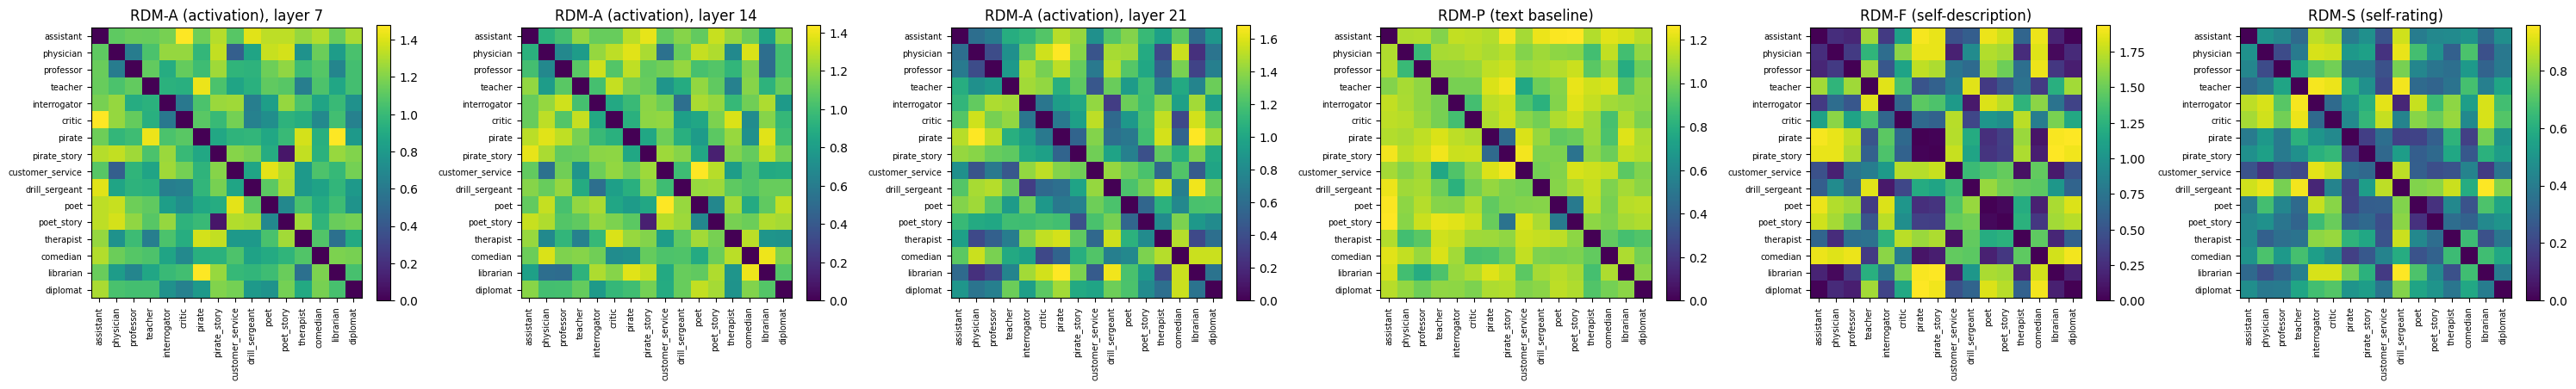

EXPECTED: RDM-F/RDM-S should visually echo RDM-A's block structure (close pairs dark in both),
more so than RDM-P does alone -- that visual match IS the primary-hypothesis result.


In [26]:
fig, axes = plt.subplots(1, len(PRIMARY_LAYERS) + 3, figsize=(5 * (len(PRIMARY_LAYERS) + 3), 4.5))
for i, L in enumerate(PRIMARY_LAYERS):
    im = axes[i].imshow(RDM_A[L], cmap="viridis")
    axes[i].set_title(f"RDM-A (activation), layer {L}")
    axes[i].set_xticks(range(K)); axes[i].set_xticklabels(persona_ids_order, rotation=90, fontsize=7)
    axes[i].set_yticks(range(K)); axes[i].set_yticklabels(persona_ids_order, fontsize=7)
    plt.colorbar(im, ax=axes[i], fraction=0.046)

for j, (name, M) in enumerate([("RDM-P (text baseline)", RDM_P),
                                ("RDM-F (self-description)", RDM_F),
                                ("RDM-S (self-rating)", RDM_S)]):
    ax = axes[len(PRIMARY_LAYERS) + j]
    im = ax.imshow(M, cmap="viridis")
    ax.set_title(name)
    ax.set_xticks(range(K)); ax.set_xticklabels(persona_ids_order, rotation=90, fontsize=7)
    ax.set_yticks(range(K)); ax.set_yticklabels(persona_ids_order, fontsize=7)
    plt.colorbar(im, ax=ax, fraction=0.046)

plt.tight_layout()
plt.savefig(os.path.join(CKPT_DIR, "lite_rdm_heatmaps.png"), dpi=120)
plt.show()
print("EXPECTED: RDM-F/RDM-S should visually echo RDM-A's block structure (close pairs dark in both),")
print("more so than RDM-P does alone -- that visual match IS the primary-hypothesis result.")

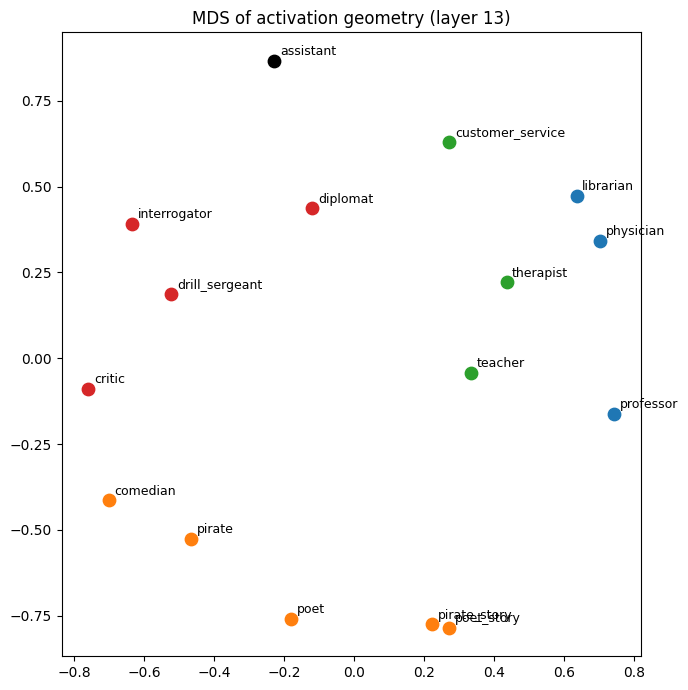

EXPECTED: close pairs (physician/professor, teacher/customer_service, interrogator/drill_sergeant,
pirate/poet) near each other; far pairs apart; the 4 surprise personas (therapist/comedian/
librarian/diplomat) land somewhere interesting -- that's worth a sentence in Results either way.


In [28]:
from sklearn.manifold import MDS
mds = MDS(n_components=2, dissimilarity="precomputed", random_state=0, normalized_stress="auto")
coords = mds.fit_transform(RDM_A[PRIMARY_LAYERS[1]])

plt.figure(figsize=(7, 7))
cluster_colors = {"anchor": "black", "expert": "tab:blue", "warm": "tab:green",
                   "cold": "tab:red", "playful": "tab:orange"}  # covers all clusters in the K=16 set
for i, p in enumerate(PERSONAS):
    c = cluster_colors.get(p["cluster"], "gray")
    plt.scatter(*coords[i], c=c, s=80)
    plt.annotate(p["id"], coords[i], fontsize=9, xytext=(4, 4), textcoords="offset points")
plt.title("MDS of activation geometry (layer 13)")
plt.tight_layout()
plt.savefig(os.path.join(CKPT_DIR, "lite_mds.png"), dpi=120)
plt.show()
print("EXPECTED: close pairs (physician/professor, teacher/customer_service, interrogator/drill_sergeant,")
print("pirate/poet) near each other; far pairs apart; the 4 surprise personas (therapist/comedian/")
print("librarian/diplomat) land somewhere interesting -- that's worth a sentence in Results either way.")

In [29]:
DIGIT_IDS = digit_ids  # from Cell 3's Check B
DIGIT_VALUES = list(range(1, 10))

def rating_readout(system_prompt, question, layer, alpha, vec, positions="last"):
    '''Returns (expected_value, digit_mass). positions="last" steers only the final prompt token.'''
    prompt_str = build_prompt(system_prompt, question)
    ids = tok(prompt_str, return_tensors="pt").to(device)
    seq_len = ids["input_ids"].shape[1]
    pos_list = None if positions == "all" else [seq_len - 1]

    h = model.model.layers[layer].register_forward_hook(make_steer_hook(vec, alpha, positions=pos_list))
    with torch.no_grad():
        logits = model(**ids).logits[0, -1].float()
    h.remove()

    probs_all = torch.softmax(logits, -1)
    p = probs_all[DIGIT_IDS]
    mass = p.sum().item()
    p_norm = (p / p.sum()).cpu().numpy()
    ev = float((p_norm * np.array(DIGIT_VALUES)).sum())
    return ev, mass

print("rating_readout defined. EXPECTED: no errors.")

rating_readout defined. EXPECTED: no errors.


In [30]:
print("=" * 70)
print("PHANTASOS-LITE NOTEBOOK -- SUMMARY REPORT")
print("=" * 70)
print(f"Model: {MODEL_NAME} | n_layers={n_layers} | hidden_size={hidden_size}")
print(f"Personas: {len(PERSONAS)} | I-set: {len(I_SET)}")
print()
print("--- Environment checks ---")
print(f"HOOK_OUTPUT_IS_TUPLE = {HOOK_OUTPUT_IS_TUPLE}")
print(f"digit_ids = {digit_ids}")
print(f"alpha=0 no-op check passed = {same_as_baseline}")
print()
print("--- S2 persona expression ---")
for p in PERSONAS:
    vals = expr_by_persona.get(p["id"], [])
    if vals:
        print(f"  {p['id']:18s} mean_expression={np.mean(vals):.2f}")
print(f"  fraction role-personas scoring >=2: {frac_ge2:.2f}  (pass: >=0.85)")
print()
print("--- S5 separability ---")
print(f"  leave-one-variant-out nearest-centroid accuracy: {acc:.3f}  (chance: {1/K:.3f})")
print()
print(f"--- Baseline RSA: activation vs. text (K={K}) ---")
for L in PRIMARY_LAYERS:
    obs, p, _ = perm_test(RDM_A[L], upper(RDM_P), n=2000)
    print(f"  layer {L}: RSA(act,text)={obs:.3f}, perm-p={p:.4f}")
print(f"  shuffled-label control RSA: {shuf_rsa:.3f}  (should be ~0)")
print()
print("--- PRIMARY RESULT: activation vs. self-report ---")
for L in PRIMARY_LAYERS:
    r = results_primary[L]
    print(f"  layer {L}: self-desc RSA={r['obs_F']:.3f} (p={r['p_F']:.4f}, partial-out-text={r['partial_F']:.3f})"
          f"  |  self-rating RSA={r['obs_S']:.3f} (p={r['p_S']:.4f}, partial-out-text={r['partial_S']:.3f})")
print(f"  RDM-F / RDM-S channel agreement: {rsa(upper(RDM_F), upper(RDM_S)):.3f}")
print()
print("Files saved to:", CKPT_DIR)
print("  - s2_descriptions.jsonl, s2_judge.jsonl, act_index.jsonl, act_vectors.npz, rdm_s_ratings.jsonl")
print("  - lite_rdm_heatmaps.png, lite_mds.png")
print("=" * 70)

PHANTASOS-LITE NOTEBOOK -- SUMMARY REPORT
Model: Qwen/Qwen2.5-1.5B-Instruct | n_layers=28 | hidden_size=1536
Personas: 16 | I-set: 8

--- Environment checks ---
HOOK_OUTPUT_IS_TUPLE = False
digit_ids = [16, 17, 18, 19, 20, 21, 22, 23, 24]
alpha=0 no-op check passed = True

--- S2 persona expression ---
  assistant          mean_expression=0.62
  physician          mean_expression=1.38
  professor          mean_expression=1.25
  teacher            mean_expression=1.75
  interrogator       mean_expression=0.62
  critic             mean_expression=1.44
  pirate             mean_expression=2.25
  pirate_story       mean_expression=1.81
  customer_service   mean_expression=0.88
  drill_sergeant     mean_expression=1.44
  poet               mean_expression=2.06
  poet_story         mean_expression=1.81
  therapist          mean_expression=1.31
  comedian           mean_expression=1.62
  librarian          mean_expression=1.12
  diplomat           mean_expression=0.94
  fraction role-personas

In [34]:
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap

PHANTASOS = {
    "surface":    "#fcfcfb",
    "ink":        "#0b0b0b",
    "ink2":       "#52514e",
    "muted":      "#898781",
    "grid":       "#e1e0d9",
    "baseline":   "#c3c2b7",
    "cat": ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6"],
    "seq": ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#2a78d6", "#1c5cab", "#104281"],
}

mpl.rcParams.update({
    "figure.facecolor": PHANTASOS["surface"], "axes.facecolor": PHANTASOS["surface"],
    "savefig.facecolor": PHANTASOS["surface"], "font.family": "sans-serif",
    "font.size": 10.5, "text.color": PHANTASOS["ink"],
    "axes.edgecolor": PHANTASOS["baseline"], "axes.labelcolor": PHANTASOS["ink2"],
    "axes.titlecolor": PHANTASOS["ink"], "axes.titleweight": "bold", "axes.titlesize": 11.5,
    "xtick.color": PHANTASOS["muted"], "ytick.color": PHANTASOS["muted"],
    "grid.color": PHANTASOS["grid"], "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "legend.fontsize": 9.5,
})

ORANGE_SEQ = ["#fdecd9", "#fad2ab", "#f5ad73", "#eb6834", "#c94a24", "#8c2f1b"]
SEQ_CMAP_obj = LinearSegmentedColormap.from_list("phantasos_orange", ORANGE_SEQ)
SEQ_CMAP_obj.set_bad(color=PHANTASOS["grid"])

def masked_for_display(M):
    """Diagonal excluded from both display and color-scale computation."""
    Mm = M.copy().astype(float)
    np.fill_diagonal(Mm, np.nan)
    return Mm

def clean_axes(ax, keep_grid_y=False):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(PHANTASOS["baseline"])
        ax.spines[side].set_linewidth(0.8)
    if keep_grid_y:
        ax.grid(True, axis="y", linewidth=0.5, alpha=0.5, color=PHANTASOS["grid"])
        ax.set_axisbelow(True)

print("Style setup loaded.")

Style setup loaded.


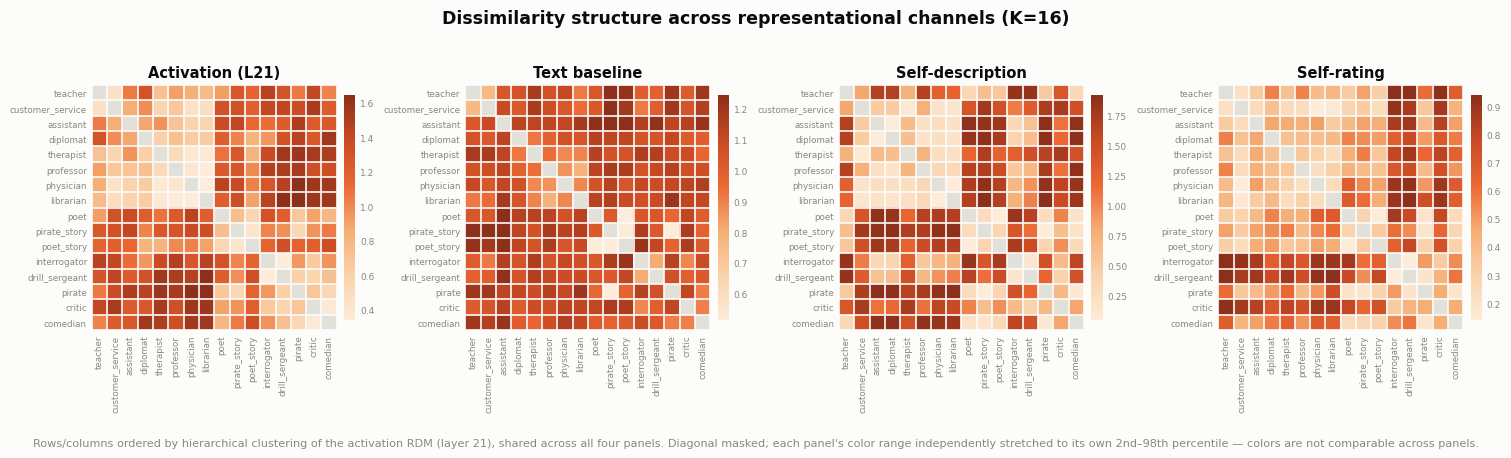

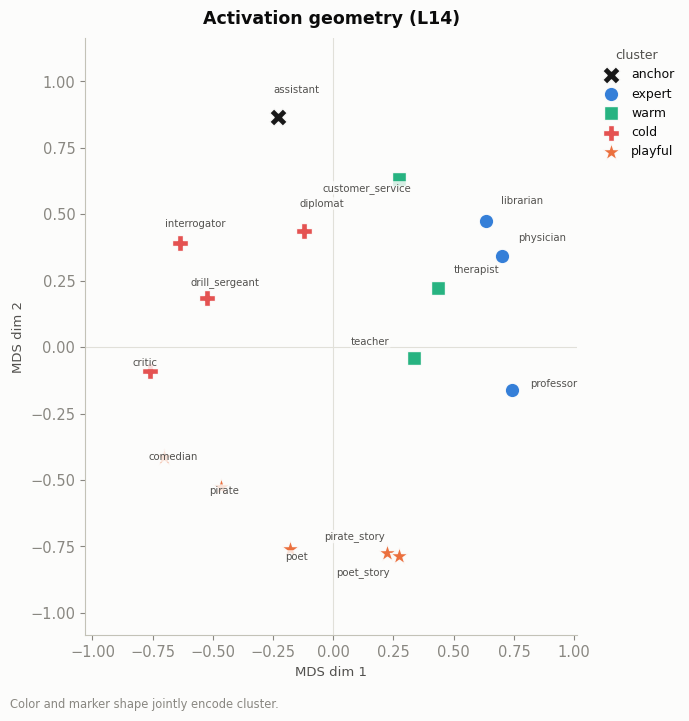

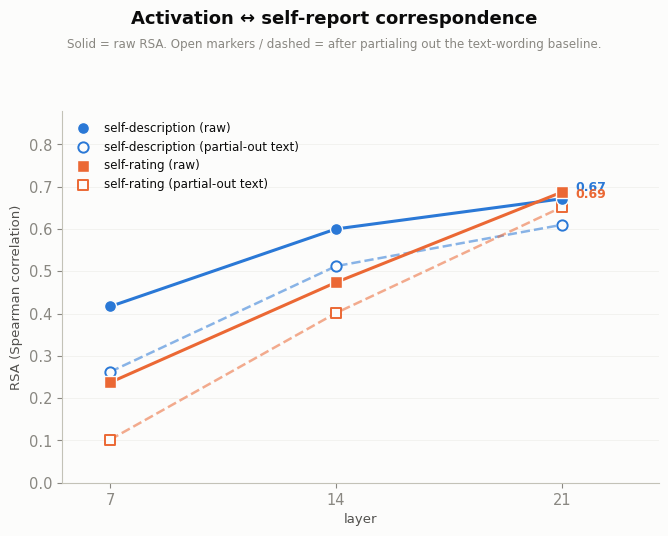

In [35]:
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform

# ============================================================
# FIGURE A (v5) -- clustering-reordered for readability, cell gridlines
# ============================================================
order_idx = leaves_list(linkage(squareform(RDM_A[21], checks=False), method="average"))
ordered_ids = [persona_ids_order[i] for i in order_idx]

def reorder(M):
    return M[np.ix_(order_idx, order_idx)]

fig, axes = plt.subplots(1, 4, figsize=(15, 3.9), constrained_layout=True)
panels = [(f"Activation (L{PRIMARY_LAYERS[-1]})", RDM_A[PRIMARY_LAYERS[-1]]), ("Text baseline", RDM_P),
          ("Self-description", RDM_F), ("Self-rating", RDM_S)]
for ax, (title, M) in zip(axes, panels):
    Mm = masked_for_display(reorder(M))
    off_diag = Mm[~np.isnan(Mm)]
    vmin, vmax = np.percentile(off_diag, 2), np.percentile(off_diag, 98)
    im = ax.imshow(Mm, cmap=SEQ_CMAP_obj, aspect="equal", vmin=vmin, vmax=vmax)
    ax.set_title(title, fontsize=10.5, pad=6, fontweight="bold")
    ax.set_xticks(range(K)); ax.set_xticklabels(ordered_ids, rotation=90, fontsize=6.3, color=PHANTASOS["muted"])
    ax.set_yticks(range(K)); ax.set_yticklabels(ordered_ids, fontsize=6.3, color=PHANTASOS["muted"])
    ax.set_xticks(np.arange(-.5, K, 1), minor=True); ax.set_yticks(np.arange(-.5, K, 1), minor=True)
    ax.grid(which="minor", color=PHANTASOS["surface"], linewidth=1.2)
    ax.tick_params(which="minor", length=0)
    for s in ax.spines.values(): s.set_visible(False)
    ax.tick_params(length=0)
    cb = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
    cb.outline.set_visible(False); cb.ax.tick_params(labelsize=6.5, color=PHANTASOS["muted"], length=0)

fig.suptitle("Dissimilarity structure across representational channels (K=16)",
             fontsize=12.5, y=1.05, color=PHANTASOS["ink"], fontweight="bold")
fig.text(0.5, -0.07,
         "Rows/columns ordered by hierarchical clustering of the activation RDM (layer 21), "
         "shared across all four panels. Diagonal masked; each panel's color range independently "
         "stretched to its own 2nd\u201398th percentile \u2014 colors are not comparable across panels.",
         ha="center", fontsize=8.1, color=PHANTASOS["muted"])
plt.savefig(os.path.join(CKPT_DIR, "fig_rdm_heatmaps.png"), dpi=200, bbox_inches="tight")
plt.savefig(os.path.join(CKPT_DIR, "fig_rdm_heatmaps_qwn1p5b.pdf"), format="pdf", bbox_inches="tight")
plt.show()

# ============================================================
# FIGURE B (v4) -- radial label placement, no clipping
# ============================================================
CLUSTER_STYLE = {
    "anchor":  dict(color=PHANTASOS["ink"],    marker="X", size=160),
    "expert":  dict(color=PHANTASOS["cat"][0], marker="o", size=110),
    "warm":    dict(color=PHANTASOS["cat"][2], marker="s", size=100),
    "cold":    dict(color="#e34948",           marker="P", size=120),
    "playful": dict(color=PHANTASOS["cat"][1], marker="*", size=190),  # stars read smaller than their size value, so bumped up
}

mds = MDS(n_components=2, dissimilarity="precomputed", random_state=0, normalized_stress="auto")
coords = mds.fit_transform(RDM_A[PRIMARY_LAYERS[1]])   # back to 13 -- this plot illustrates the S5 separability
                                          # result, which was computed at L=13, not the primary RSA peak
fig, ax = plt.subplots(figsize=(7, 7))
ax.axhline(0, color=PHANTASOS["grid"], linewidth=0.8, zorder=1)
ax.axvline(0, color=PHANTASOS["grid"], linewidth=0.8, zorder=1)

centroid = coords.mean(axis=0)
MANUAL_NUDGE = {
    "pirate_story": (-45, 10), "poet_story": (-45, -14),
    "teacher": (-45, 10), "customer_service": (-55, -8),  # near-centroid points, radial direction unreliable -- force a clean leftward offset
}

seen = set()
for i, p in enumerate(PERSONAS):
    st = CLUSTER_STYLE[p["cluster"]]
    lbl = p["cluster"] if p["cluster"] not in seen else None
    seen.add(p["cluster"])
    ax.scatter(*coords[i], c=st["color"], marker=st["marker"], s=st["size"],
               edgecolors=PHANTASOS["surface"], linewidths=1.0, label=lbl, zorder=3, alpha=0.95)
    if p["id"] in MANUAL_NUDGE:
        dx, dy = MANUAL_NUDGE[p["id"]]
    else:
        d = coords[i] - centroid
        dist = np.linalg.norm(d)
        d = d / (dist + 1e-6)
        dx, dy = d[0] * 13, d[1] * 13 + 5   # smaller radial scale -- labels stay close to their marker
    ax.annotate(p["id"], coords[i], fontsize=7.3, color=PHANTASOS["ink2"],
                xytext=(dx, dy), textcoords="offset points", zorder=5, clip_on=False,
                bbox=dict(boxstyle="round,pad=0.12", facecolor=PHANTASOS["surface"],
                          edgecolor="none", alpha=0.82))

clean_axes(ax)
ax.margins(0.18)
ax.set_xlabel("MDS dim 1", fontsize=9.5); ax.set_ylabel("MDS dim 2", fontsize=9.5)
ax.set_title(f"Activation geometry (L{PRIMARY_LAYERS[1]})", fontsize=12.5, fontweight="bold", pad=10)
leg = ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), title="cluster",
                 title_fontsize=9, fontsize=9, handletextpad=0.6)
leg.get_title().set_color(PHANTASOS["ink2"])
fig.text(0.02, -0.02, "Color and marker shape jointly encode cluster.",
         fontsize=8.3, color=PHANTASOS["muted"])
plt.tight_layout()
plt.savefig(os.path.join(CKPT_DIR, "fig_mds.png"), dpi=200, bbox_inches="tight")
plt.savefig(os.path.join(CKPT_DIR, "fig_mds_qwn1p5b.pdf"), format="pdf", bbox_inches="tight")
plt.show()
# ============================================================
# FIGURE C (v4) -- y-axis starts exactly at 0, no duplicate zero-line
# ============================================================
fig, ax = plt.subplots(figsize=(6.8, 5.4))
layers = PRIMARY_LAYERS
c_desc, c_rate = PHANTASOS["cat"][0], PHANTASOS["cat"][1]

def line_with_points(ys, color, marker, dashed, label):
    style = "--" if dashed else "-"
    ax.plot(layers, ys, style, color=color, linewidth=1.8 if dashed else 2.2,
             alpha=0.55 if dashed else 1, zorder=2 if dashed else 3)
    if dashed:
        ax.scatter(layers, ys, facecolors=PHANTASOS["surface"], edgecolors=color, linewidths=1.4,
                    s=55, marker=marker, zorder=3, label=label)
    else:
        ax.scatter(layers, ys, color=color, s=75, marker=marker, zorder=4,
                    edgecolors=PHANTASOS["surface"], linewidths=1, label=label)
    return ys

y1 = line_with_points([results_primary[L]["obs_F"] for L in layers], c_desc, "o", False, "self-description (raw)")
y2 = line_with_points([results_primary[L]["partial_F"] for L in layers], c_desc, "o", True, "self-description (partial-out text)")
y3 = line_with_points([results_primary[L]["obs_S"] for L in layers], c_rate, "s", False, "self-rating (raw)")
y4 = line_with_points([results_primary[L]["partial_S"] for L in layers], c_rate, "s", True, "self-rating (partial-out text)")

ax.annotate(f"{y1[-1]:.2f}", (layers[-1], y1[-1]), xytext=(10, 6), textcoords="offset points",
            fontsize=9, color=c_desc, fontweight="bold")
ax.annotate(f"{y3[-1]:.2f}", (layers[-1], y3[-1]), xytext=(10, -4), textcoords="offset points",
            fontsize=9, color=c_rate, fontweight="bold")

ax.set_xticks(layers); ax.set_xlabel("layer", fontsize=9.5)
ax.set_ylabel("RSA (Spearman correlation)", fontsize=9.5)
ax.set_xlim(layers[0] - 1.5, layers[-1] + 3)
ax.set_ylim(0, 0.88)  # starts exactly at 0 -- the bottom spine itself IS the zero line now
clean_axes(ax, keep_grid_y=True)
ax.legend(loc="upper left", fontsize=8.6, handlelength=1.8)

fig.suptitle("Activation \u2194 self-report correspondence", fontsize=13, fontweight="bold", y=0.985)
fig.text(0.5, 0.915, "Solid = raw RSA. Open markers / dashed = after partialing out the text-wording baseline.",
         ha="center", fontsize=8.6, color=PHANTASOS["muted"])
plt.tight_layout(rect=[0, 0, 1, 0.89])
plt.savefig(os.path.join(CKPT_DIR, "fig_rsa_summary.png"), dpi=200, bbox_inches="tight")
plt.savefig(os.path.join(CKPT_DIR, "fig_rsa_summary_qwn1p5b.pdf"), format="pdf", bbox_inches="tight")
plt.show()

In [ ]:
from google.colab import files as colab_files

def save_and_download(fig, name):
    pdf_path = f"/content/{name}.pdf"       # local Colab runtime disk, NOT Drive -- avoids the full-quota problem
    fig.savefig(pdf_path, format="pdf", bbox_inches="tight")
    colab_files.download(pdf_path)
    print(f"Saved + downloading: {name}.pdf")